**GPU checkup**

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

I0000 00:00:1791532948.920436    2915 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791532949.885736    2915 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791532953.539610    2915 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
Num GPUs Available:  1


**Data Loading**

In [4]:
import os 
from pathlib import Path
root_dir = Path(os.getcwd()).parent
Data_dir = root_dir / "Data"
print("Data directory:", Data_dir)

Data directory: /mnt/d/Intel Image Classification/Intel-Image-Scene-Classification/Data


In [6]:
from pathlib import Path

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42
VALIDATION_SPLIT = 0.1

DATA_DIR = Path(Data_dir)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR}")

DATASET_ARGS = {
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "label_mode": "int",  # Four classes: buildings, forest, glacier, mountain
}


def load_dataset(subset: str):
    return tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=VALIDATION_SPLIT,
        subset=subset,
        seed=SEED,
        **DATASET_ARGS,
    )


train_ds = load_dataset("training")
val_ds = load_dataset("validation")

overlap = set(train_ds.file_paths) & set(val_ds.file_paths)
assert not overlap, f"train/validation leakage: {len(overlap)} shared images"

print(f"Dataset directory: {DATA_DIR}")
print(f"Train images: {len(train_ds.file_paths)}")
print(f"Validation images: {len(val_ds.file_paths)}")

class_names = train_ds.class_names
print("Classes:", class_names)

Found 8942 files belonging to 4 classes.
Using 8048 files for training.


I0000 00:00:1791533754.540250    2915 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 8942 files belonging to 4 classes.
Using 894 files for validation.
Dataset directory: /mnt/d/Intel Image Classification/Intel-Image-Scene-Classification/Data
Train images: 8048
Validation images: 894
Classes: ['buildings', 'forest', 'glacier', 'mountain']


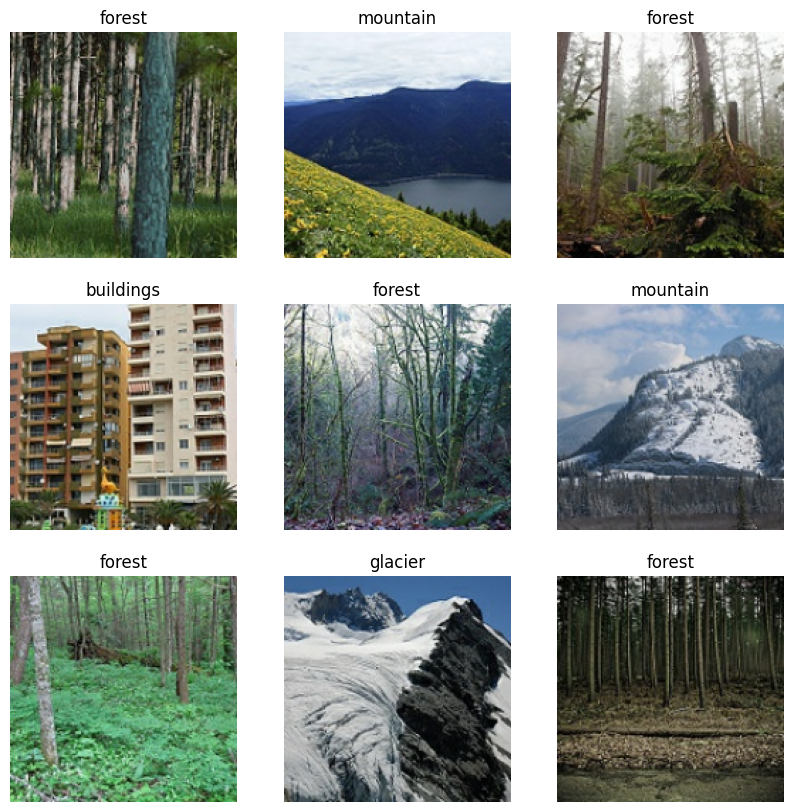

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1): #Grabs only the first batch 
                                       # from the dataset. If your batch size is 32, this single step pulls 32 images and 32 labels.
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")